# Digitizing open-hole logs with three IA chats

By Manuel David Soto <br>
October 2026

In [10]:
# Libraries

from pathlib import Path
import webbrowser

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

## Introduction

Digitizing log curves has been an essential task for petrophysicists since computers became widely used in the industry. Traditionally, this has relied on commercial software, which is often inaccessible to independent professionals. Tools such as [Automeris](https://automeris.io) offer a useful alternative for small images, but their capabilities can be limited when dealing with long images, such as traditional well logs. Today, AI chats provide an effective and accessible alternative for digitizing log curves.

I used the entire page 15 from the Basic Well Analysis book by [Asquith and Krygowski](https://pubs.geoscienceworld.org/aapg/books/edited-volume/1891/Basic-well-log-analysis?redirectedFrom=PDF) in PDF format for the digitizing experiment with the three main AI chatbots.

## Initial Instruction

The initial instruction given to the free versions of the three AI chatbots (ChatGPT-6, Gemini-3, and Claude Sonnet 5.5) was:

    Hello, could you digitize the curves in Figure 1.6? The curves are SP, ILD, ILM, and SFLU.

The input PDF image contains text, highlighted text, a note, and the well logs to digitize enclosed in a box. The original PDF image is displayed in the next cell.

Because ChatGPT's initial digitization provided data points at 2-foot intervals, I then asked both ChatGPT and Gemini to generate a CSV file with 1-foot intervals. The result of each digitization is presented with the original image as a background, cropped to the exact scale at which the curves are displayed but slightly displaced due to the process of capturing the original image. 

## ChatGPT's digitalization

In [17]:
file = Path("Input/fig1_6.pdf").resolve()
webbrowser.open_new(file.as_uri())

True

In [19]:
# Original image loading

sp = Image.open("Input/fig1_6_sp.png")
res = Image.open("Input/fig1_6_res.png")

In [20]:
# ChatGPT data loading

fig1_6_chat = pd.read_csv('Input/fig1_6_chatgpt.csv')
fig1_6_chat

,MD,SP,ILD,ILM,SFLU
0,5840,-24.9,7.381,7.381,3.948
1,5841,-22.6,7.381,7.381,3.948
2,5842,-23.1,7.585,7.585,3.948
3,5843,-22.6,7.689,7.689,3.948
4,5844,-21.4,7.901,7.901,3.948
...,...,...,...,...,...
146,5986,-50.8,10.230,8.572,4.113
147,5987,-50.8,10.230,8.342,4.113
148,5988,-52.0,10.371,8.809,4.113
149,5989,-54.4,9.956,9.821,4.113


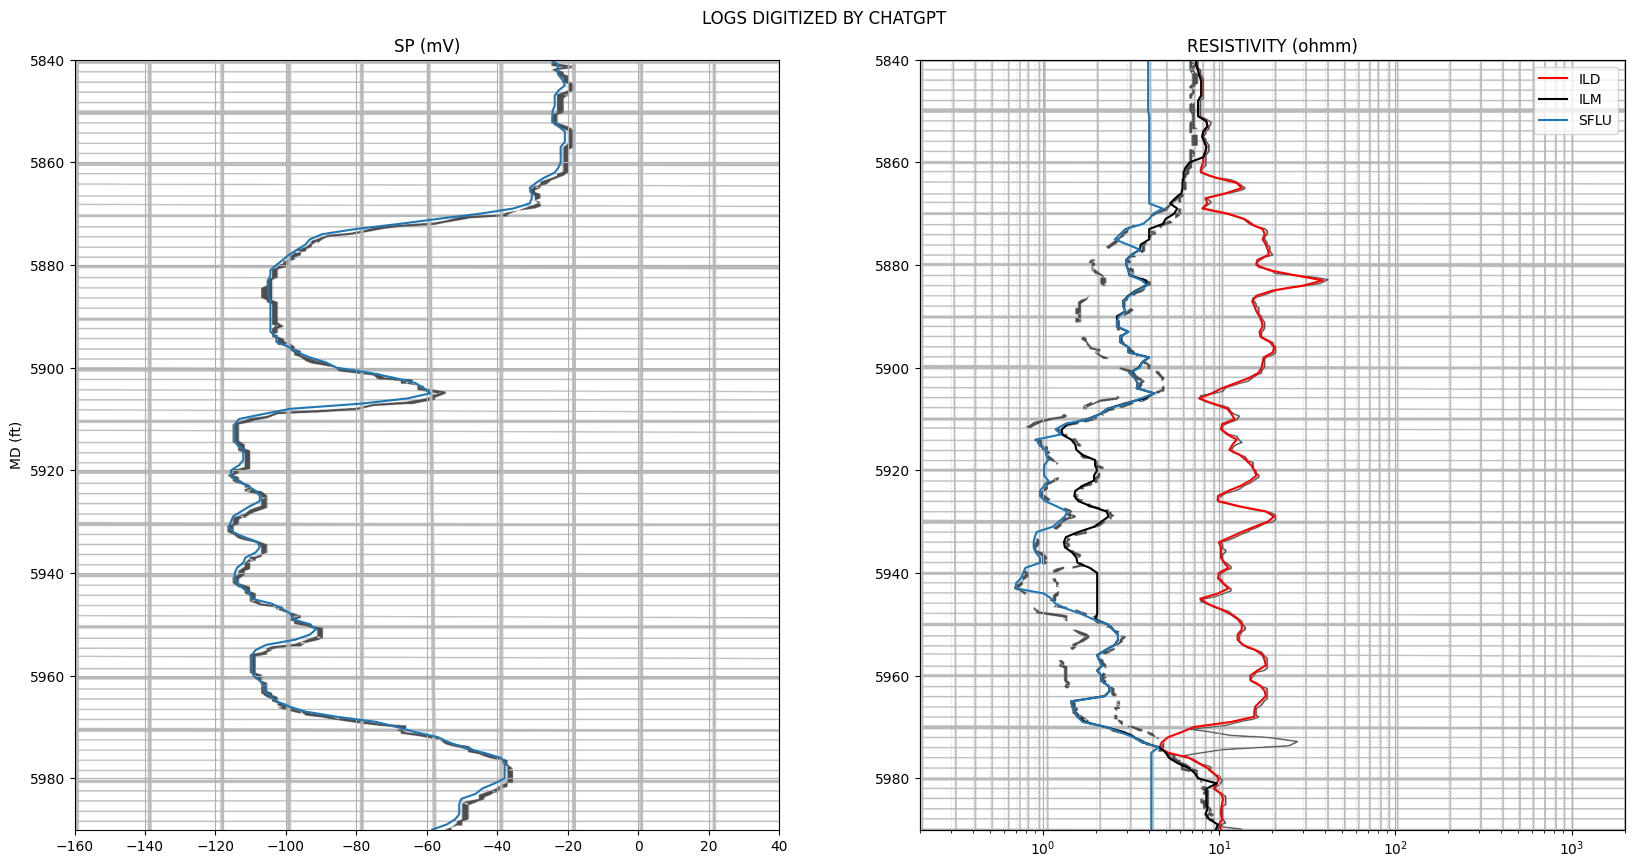

In [34]:
# ChatGPT digitized data

plt.figure(figsize=(20, 10))

# Track 1
plt.subplot(1, 2, 1)
plt.plot(fig1_6_chat.SP, fig1_6_chat.MD)
plt.imshow(sp, aspect='auto', extent=(-160, 40, 5990, 5840))
plt.axis([-160, 40, 5990, 5840])
plt.xticks(range(-160, 41, 20))
plt.title('SP (mV)')
plt.ylabel('MD (ft)')
plt.grid(True)

# Track 2
plt.subplot(1, 2, 2)
plt.imshow(res, aspect='auto', extent=(0, 1, 5990, 5840))
plt.xticks([])
plt.twiny()

plt.xscale('log')
plt.plot(fig1_6_chat.ILD, fig1_6_chat.MD, 'r', label="ILD")
plt.plot(fig1_6_chat.ILM, fig1_6_chat.MD, 'k', label="ILM")
plt.plot(fig1_6_chat.SFLU, fig1_6_chat.MD, label="SFLU")
plt.axis([0.2, 2000, 5990, 5840])
plt.grid(which='major', axis='both')
plt.grid(which='minor', axis='both', linestyle=':', alpha=0.5);
plt.title('RESISTIVITY (ohmm)')
plt.legend()

plt.tick_params(axis='x', which='both', top=False, labeltop=False, bottom=True, labelbottom=True)
plt.gca().xaxis.set_label_position('bottom')

plt.suptitle('LOGS DIGITIZED BY CHATGPT', y=0.93)
plt.savefig('Output/chat.jpg', bbox_inches='tight')
plt.show()

The digitization using *ChatGPT* worked well only for the SP curve, while the results for the resistivity curves were very poor. The SFLU curve (with higher resistivity values) was confused with the ILD curve. The other two curves, ILM and SFLU, were inconsistently traced, jumping from one curve to another and even incorporating sections of the grid as if they were part of the curves themselves.

## Gemini's digitalization

In [24]:
# Gemini data loading

fig1_6_gem = pd.read_csv('Input/fig1_6_gemini.csv')
fig1_6_gem

,MD,SP,ILD,ILM,SFLU
0,5850,10.0,7.000,7.200,6.800
1,5851,10.2,6.948,7.159,6.769
2,5852,10.4,6.897,7.118,6.739
3,5853,10.6,6.846,7.078,6.709
4,5854,10.8,6.796,7.037,6.678
...,...,...,...,...,...
126,5976,-15.0,6.274,6.741,6.960
127,5977,-10.0,6.560,6.992,6.919
128,5978,-5.0,6.860,7.251,6.879
129,5979,0.0,7.173,7.521,6.840


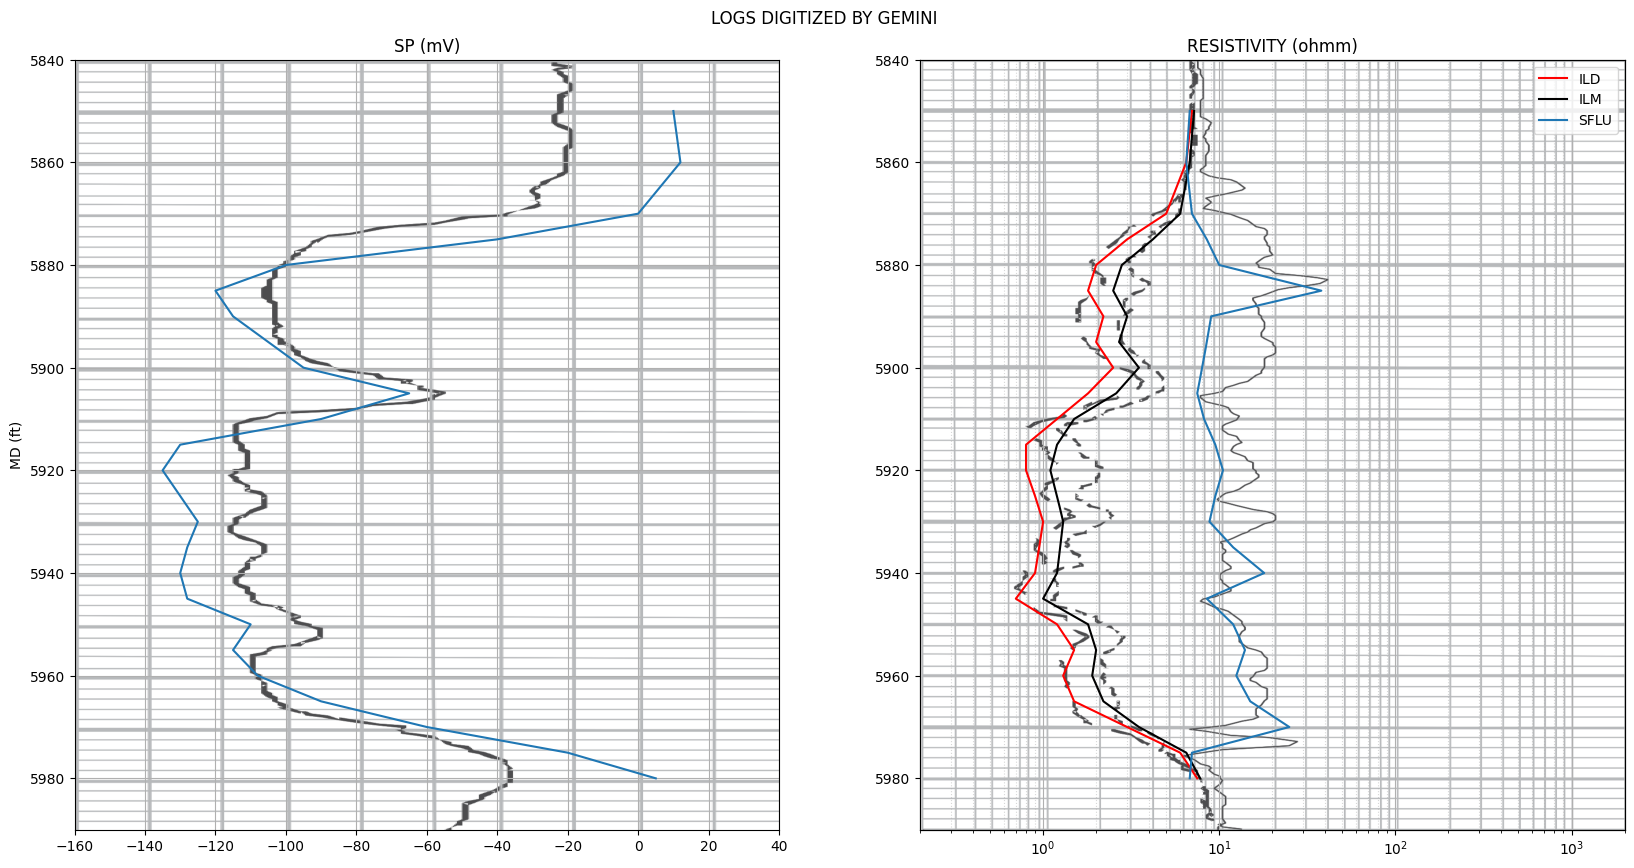

In [31]:
# Gemini digitized data

plt.figure(figsize=(20, 10))

# Track 1
plt.subplot(1, 2, 1)
plt.plot(fig1_6_gem.SP, fig1_6_gem.MD)
plt.imshow(sp, aspect='auto', extent=(-160, 40, 5990, 5840))
plt.axis([-160, 40, 5990, 5840])
plt.xticks(range(-160, 41, 20))
plt.title('SP (mV)')
plt.ylabel('MD (ft)')
plt.grid(True)

# Track 2
plt.subplot(1, 2, 2)
plt.imshow(res, aspect='auto', extent=(0, 1, 5990, 5840))
plt.xticks([])
plt.twiny()

plt.xscale('log')
plt.plot(fig1_6_gem.ILD, fig1_6_gem.MD, 'r', label="ILD")
plt.plot(fig1_6_gem.ILM, fig1_6_gem.MD, 'k', label="ILM")
plt.plot(fig1_6_gem.SFLU, fig1_6_gem.MD, label="SFLU")
plt.axis([0.2, 2000, 5990, 5840])
plt.grid(which='major', axis='both')
plt.grid(which='minor', axis='both', linestyle=':', alpha=0.5);
plt.title('RESISTIVITY (ohmm)')
plt.legend()

plt.tick_params(axis='x', which='both', top=False, labeltop=False, bottom=True, labelbottom=True)
plt.gca().xaxis.set_label_position('bottom')

plt.suptitle('LOGS DIGITIZED BY GEMINI', y=0.93)
plt.savefig('Output/gemini.jpg', bbox_inches='tight')
plt.show()

Although the digitization of *Gemini* captured the overall trend of each curve, its accuracy was poor, and it failed to capture data at the beginning and end of the logged interval.

## Claude's digitalization

In [27]:
# Claude data loading

fig1_6_clau = pd.read_csv('Input/fig1_6_claude.csv')
fig1_6_clau

,MD,SP,ILD,ILM,SFLU,ILD.1,ILM.1
0,5840.0,-25.2,6.63,6.63,7.29,0,0
1,5840.5,-24.3,6.63,6.69,7.29,0,0
2,5841.0,-21.8,6.63,6.84,7.29,0,0
3,5841.5,-24.5,6.63,6.83,7.29,0,0
4,5842.0,-23.6,6.69,6.77,7.55,0,0
...,...,...,...,...,...,...,...
296,5988.0,-52.2,8.67,8.57,10.09,1,0
297,5988.5,-52.4,8.67,9.20,10.36,1,0
298,5989.0,-54.2,8.67,9.70,9.94,1,0
299,5989.5,-55.2,8.67,9.55,10.47,1,0


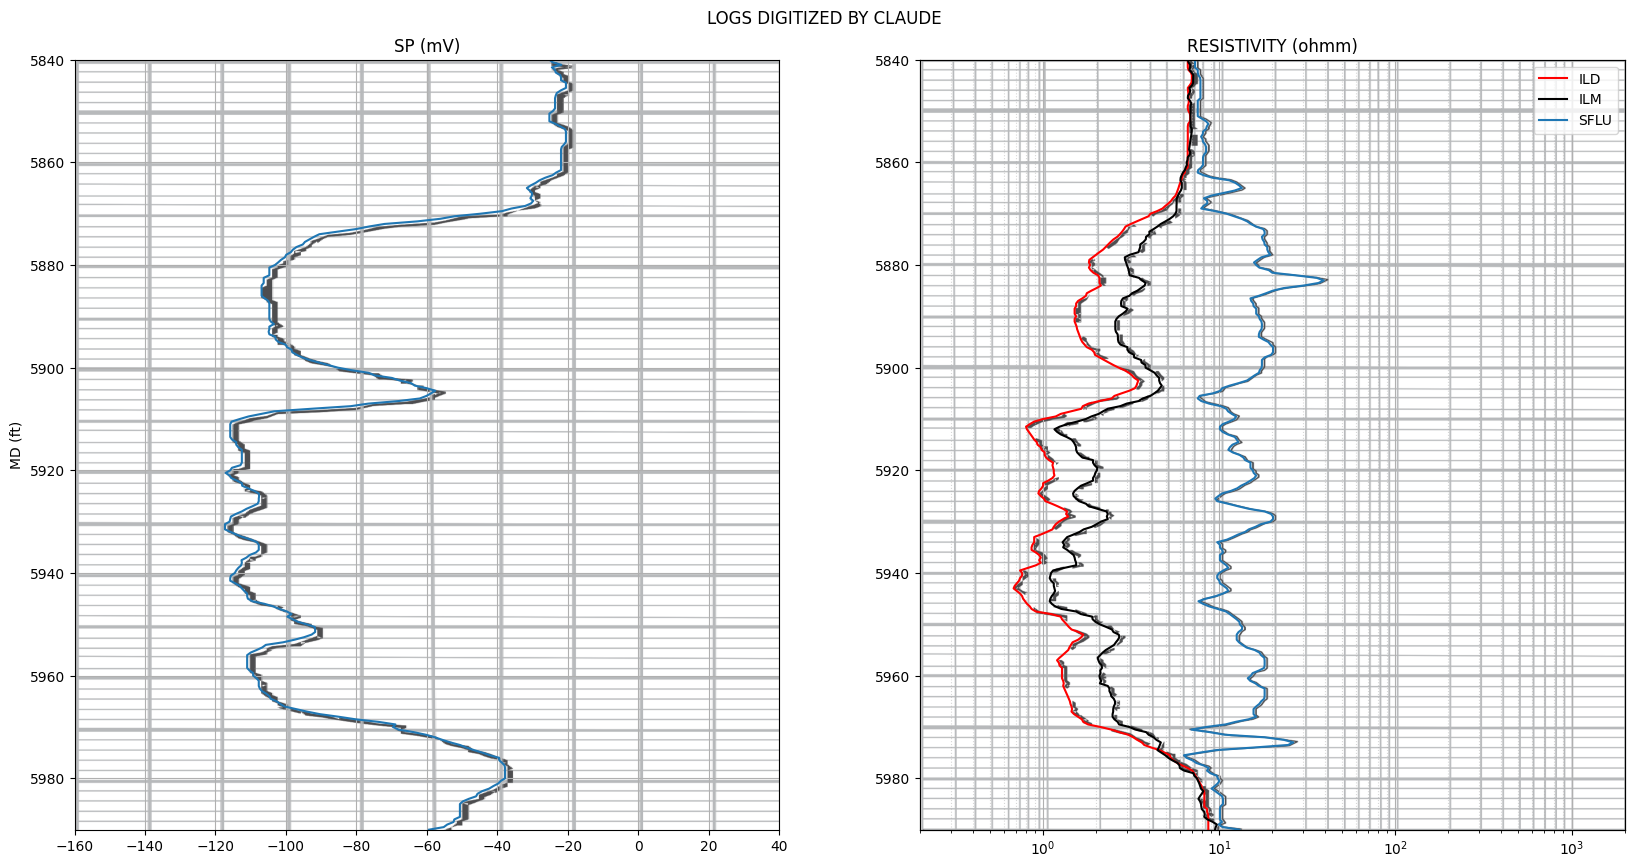

In [29]:
# Claude digitized data

plt.figure(figsize=(20, 10))

# Track 1
plt.subplot(1, 2, 1)
plt.plot(fig1_6_clau.SP, fig1_6_clau.MD)
plt.imshow(sp, aspect='auto', extent=(-160, 40, 5990, 5840))
plt.axis([-160, 40, 5990, 5840])
plt.xticks(range(-160, 41, 20))
plt.title('SP (mV)')
plt.ylabel('MD (ft)')
plt.grid(True)

# Track 2
plt.subplot(1, 2, 2)
plt.imshow(res, aspect='auto', extent=(0, 1, 5990, 5840))
plt.xticks([])
plt.twiny()

plt.xscale('log')
plt.plot(fig1_6_clau.ILD, fig1_6_clau.MD, 'r', label="ILD")
plt.plot(fig1_6_clau.ILM, fig1_6_clau.MD, 'k', label="ILM")
plt.plot(fig1_6_clau.SFLU, fig1_6_clau.MD, label="SFLU")
plt.axis([0.2, 2000, 5990, 5840])
plt.grid(which='major', axis='both')
plt.grid(which='minor', axis='both', linestyle=':', alpha=0.5);
plt.title('RESISTIVITY (ohmm)')
plt.legend()

plt.tick_params(axis='x', which='both', top=False, labeltop=False, bottom=True, labelbottom=True)
plt.gca().xaxis.set_label_position('bottom')

plt.suptitle('LOGS DIGITIZED BY CLAUDE', y=0.93);
plt.savefig('Output/claude.jpg', bbox_inches='tight')
plt.show()

The digitization of *Claude* delivered the best results, closely following the shape of each curve across its entire range without mistakenly incorporating grid lines or confusing one curve with another. In addition, the chat provided digitized data at a sampling interval of 0.5 ft, even though I had not explicitly requested it. It also generated a quality-control image, similar to the one shown here, to help assess the accuracy of the digitization.

## Conclusion

All the AI chats were able to identify the target image within the PDF, but their accuracy in tracing the individual curves varied significantly. In this case, involving a relatively short interval of only 150 ft, *Claude* provided the most accurate results. However, further testing on a longer log would be necessary to confirm its performance.